# 01 — PAD-UFES-20 Dataset Audit

## Dataset Overview

This project uses **PAD-UFES-20**, a publicly available multimodal skin-lesion dataset collected through the Dermatological and Surgical Assistance Program (PAD) at the Federal University of Espírito Santo (UFES), Brazil.

The dataset contains **2,298 smartphone clinical images from 1,373 patients and 1,641 skin lesions**. Each sample combines a clinical image with structured patient and lesion metadata. The dataset represents six diagnostic classes: **Actinic Keratosis (ACK), Basal Cell Carcinoma (BCC), Melanoma (MEL), Nevus (NEV), Squamous Cell Carcinoma (SCC), and Seborrheic Keratosis (SEK)**. Clinical metadata includes patient characteristics and lesion information such as age, anatomical region, lesion symptoms, skin type, and lesion diameter.

The dataset provides a practical scale for the computational scope of this project. Its **2,298 multimodal samples are manageable within Google Colab**, while still supporting patient-grouped cross-validation and comparison of multiple multimodal learning approaches. A lightweight pretrained visual backbone will be used to make repeated experiments computationally feasible. The dataset is class-imbalanced, particularly for melanoma, which will be considered explicitly in the training and evaluation protocol.

The dataset was obtained from the official **Mendeley Data** repository and is distributed under the **CC BY 4.0** licence.

**Dataset source:**  
Pacheco, A. G. C., et al. (2020). *PAD-UFES-20: A skin lesion dataset composed of patient data and clinical images collected from smartphones*. Mendeley Data, Version 1.  
https://doi.org/10.17632/zr7vgbcyr2.1

## Audit Objective

This notebook performs an initial audit of PAD-UFES-20 before model development. The audit examines:

- dataset size and structure,
- diagnostic class distribution,
- patient and lesion duplication,
- missing-value patterns,
- metadata characteristics,
- potential leakage variables,
- image availability and dimensions,
- patient-grouped cross-validation folds.

The purpose is to identify data-quality and leakage risks and establish a reproducible modelling protocol before preprocessing and model training.

## 1. Setup

Import the libraries required for tabular analysis, file handling, and visualisation.

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 2. Connect Google Drive

The dataset is stored in Google Drive because the image files are too large to keep in the GitHub repository.

In [11]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. Define Dataset Paths

Define the locations of the metadata file and extracted image directory.

In [14]:
PROJECT_ROOT = Path("/content/drive/MyDrive/PAD_UFES_Capstone")

METADATA_PATH = PROJECT_ROOT /  "metadata.csv"
IMAGE_DIR = PROJECT_ROOT / "images"

print("Metadata:", METADATA_PATH)
print("Images:", IMAGE_DIR)

Metadata: /content/drive/MyDrive/PAD_UFES_Capstone/metadata.csv
Images: /content/drive/MyDrive/PAD_UFES_Capstone/images


## 4. Load Metadata

Load the PAD-UFES-20 metadata and inspect the dataset dimensions and available variables.

In [15]:
df = pd.read_csv(METADATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2298, 26)


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,cancer_history,has_piped_water,has_sewage_system,fitspatrick,region,diameter_1,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ARM,NaN,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,True,True,True,3.0,NECK,6.0,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FACE,NaN,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HAND,NaN,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,False,False,False,1.0,FOREARM,5.0,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True


## 5. Inspect Dataset Variables

Review column names, data types, and unique-value counts to understand the structure of the clinical metadata.

In [16]:
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "unique_values": df.nunique(dropna=False),
    "missing_values": df.isna().sum(),
})

display(summary)

,dtype,unique_values,missing_values
patient_id,object,1373,0
lesion_id,int64,1641,0
smoke,object,3,804
drink,object,3,804
background_father,object,14,818
background_mother,object,12,822
age,int64,84,0
pesticide,object,3,804
gender,object,3,804
skin_cancer_history,object,3,804


## 6. Class Distribution

Examine the number of images in each diagnostic class and identify class imbalance.

,images
diagnostic,
BCC,845
ACK,730
NEV,244
SEK,235
SCC,192
MEL,52


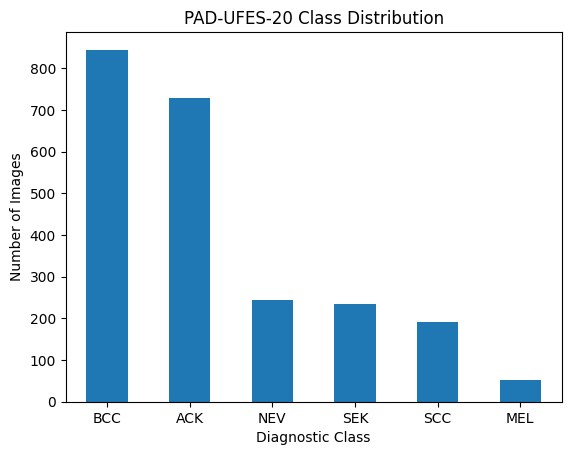

In [17]:
class_counts = df["diagnostic"].value_counts().sort_values(ascending=False)

display(class_counts.to_frame("images"))

class_counts.plot(kind="bar")
plt.title("PAD-UFES-20 Class Distribution")
plt.xlabel("Diagnostic Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

## 7. Patient and Lesion Structure

Check how many unique patients and lesions are represented and determine whether multiple images belong to the same patient or lesion.

This is important because random image-level splitting could place related samples in both training and test sets.

In [18]:
print("Images:", len(df))
print("Unique patients:", df["patient_id"].nunique())
print("Unique lesions:", df["lesion_id"].nunique())

print("\nImages per patient:")
display(df.groupby("patient_id").size().value_counts().sort_index())

print("\nImages per lesion:")
display(df.groupby("lesion_id").size().value_counts().sort_index())

Images: 2298
Unique patients: 1373
Unique lesions: 1641

Images per patient:


,count
1,829
2,328
3,132
4,42
5,21
6,12
7,6
10,3



Images per lesion:


,count
1,1129
2,396
3,95
4,17
5,2
6,1
8,1


## 8. Diagnosis Diversity Within Patients

Check whether individual patients can have lesions belonging to more than one diagnostic class.

In [19]:
diagnoses_per_patient = (
    df.groupby("patient_id")["diagnostic"]
    .nunique()
)

print("Patients with more than one diagnosis:",
      (diagnoses_per_patient > 1).sum())

display(
    diagnoses_per_patient
    .value_counts()
    .sort_index()
    .to_frame("patients")
)

Patients with more than one diagnosis: 179


,patients
diagnostic,
1,1194
2,166
3,10
4,3


## 9. Missing-Value Analysis

Measure missingness across all metadata variables and identify whether missing data occur independently or as structured blocks.

In [20]:
missing = (
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

missing["missing_percent"] = (
    missing["missing_count"] / len(df) * 100
)

display(missing)

,missing_count,missing_percent
background_mother,822,35.770235
background_father,818,35.596171
pesticide,804,34.986945
gender,804,34.986945
drink,804,34.986945
smoke,804,34.986945
skin_cancer_history,804,34.986945
has_sewage_system,804,34.986945
has_piped_water,804,34.986945
cancer_history,804,34.986945


## 10. Investigate Structured Missingness

Several clinical variables may be missing together. This cell checks whether they form a consistent missing-data pattern that could reveal data-collection cohorts.

In [21]:
candidate_missing_fields = [
    "smoke",
    "drink",
    "background_father",
    "background_mother",
    "pesticide",
    "gender",
    "skin_cancer_history",
    "cancer_history",
    "has_piped_water",
    "has_sewage_system",
    "fitspatrick",
    "diameter_1",
    "diameter_2",
]

existing_fields = [
    col for col in candidate_missing_fields
    if col in df.columns
]

df["missing_field_count"] = (
    df[existing_fields]
    .isna()
    .sum(axis=1)
)

display(
    df["missing_field_count"]
    .value_counts()
    .sort_index()
    .to_frame("rows")
)

,rows
missing_field_count,
0,1474
1,8
2,12
13,804


## 11. Missingness by Diagnostic Class

Check whether structured missingness is associated with the diagnostic target.

If missingness strongly identifies particular classes, using missing-value indicators may introduce unintended dataset-collection bias.

In [22]:
missing_by_class = pd.crosstab(
    df["missing_field_count"],
    df["diagnostic"]
)

display(missing_by_class)

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
missing_field_count,,,,,,
0,273,845,52,72,192,40
1,7,0,0,1,0,0
2,3,0,0,2,0,7
13,447,0,0,169,0,188


## 12. Inspect Potential Leakage Variables

Some variables may encode diagnostic workflow rather than patient characteristics.

The biopsy indicator is examined separately to determine whether it is strongly associated with the target.

In [23]:
if "biopsed" in df.columns:
    biopsy_table = pd.crosstab(
        df["biopsed"],
        df["diagnostic"],
        normalize="index"
    )

    display(biopsy_table.round(3))

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
biopsed,,,,,,
False,0.577,0.00,0.000,0.192,0.000,0.230
True,0.133,0.63,0.039,0.045,0.143,0.011


## 13. Define Leakage-Safe Metadata

The primary multimodal experiments will use clinical variables that:
- are available for all samples,
- are not identifiers,
- do not directly encode the diagnostic workflow,
- and do not belong to the strongly cohort-linked missing-data block.

In [24]:
SAFE_METADATA = [
    "age",
    "region",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation",
]

display(df[SAFE_METADATA].head())

print("\nMissing values:")
display(df[SAFE_METADATA].isna().sum())

,age,region,itch,grew,hurt,changed,bleed,elevation
0,8,ARM,False,False,False,False,False,False
1,55,NECK,True,True,False,True,True,True
2,77,FACE,True,False,False,False,False,False
3,75,HAND,True,False,False,False,False,False
4,79,FOREARM,True,True,False,False,True,True



Missing values:


,0
age,0
region,0
itch,0
grew,0
hurt,0
changed,0
bleed,0
elevation,0


## 14. Inspect Safe Metadata Distributions

Review the distributions of the selected clinical variables before designing the metadata encoder.

In [25]:
for column in SAFE_METADATA:
    print(f"\n### {column}")
    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("count")
        .head(20)
    )


### age


,count
age,
55,73
73,73
58,70
71,66
62,66
75,66
57,63
65,62
53,60



### region


,count
region,
FACE,570
FOREARM,392
CHEST,280
BACK,248
ARM,192
NOSE,158
HAND,126
NECK,93
EAR,73



### itch


,count
itch,
True,1455
False,837
UNK,6


... (6 outputs left out)


### bleed


,count
bleed,
False,1678
True,614
UNK,6



### elevation


,count
elevation,
True,1433
False,863
UNK,2


## 15. Extract and Verify Image Files

The PAD-UFES-20 images are stored as ZIP archives in Google Drive.

The archives are extracted temporarily to the Colab runtime so the images can be accessed efficiently during analysis and training.

In [28]:
from pathlib import Path
import zipfile

ZIP_DIR = PROJECT_ROOT
IMAGE_DIR = Path("/content/pad_images")

IMAGE_DIR.mkdir(parents=True, exist_ok=True)

zip_files = [
    ZIP_DIR / "imgs_part_1.zip",
    ZIP_DIR / "imgs_part_2.zip",
    ZIP_DIR / "imgs_part_3.zip",
]

for zip_path in zip_files:
    print(f"Extracting {zip_path.name}...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(IMAGE_DIR)

print("\nExtraction complete.")

Extracting imgs_part_1.zip...
Extracting imgs_part_2.zip...
Extracting imgs_part_3.zip...

Extraction complete.


### Verify Extracted Images

Confirm that every image referenced in the metadata is available after extraction.

In [29]:
image_files = {
    path.name
    for path in IMAGE_DIR.rglob("*")
    if path.is_file()
}

metadata_images = set(df["img_id"])

missing_images = metadata_images - image_files
extra_images = image_files - metadata_images

print("Metadata image IDs:", len(metadata_images))
print("Extracted image files:", len(image_files))
print("Missing images:", len(missing_images))
print("Extra images:", len(extra_images))

assert len(missing_images) == 0, "Some metadata images are missing."

print("\n✓ All metadata images were found.")

Metadata image IDs: 2298
Extracted image files: 2298
Missing images: 0
Extra images: 0

✓ All metadata images were found.


## 16. Inspect Image Dimensions

Analyse image width, height, and aspect ratio to understand image-size variability and inform the later preprocessing strategy.

In [33]:
# Map each image filename to its extracted location
image_paths = {
    path.name: path
    for path in IMAGE_DIR.rglob("*")
    if path.is_file()
}

image_info = []

for image_name in df["img_id"]:
    path = image_paths[image_name]

    with Image.open(path) as img:
        width, height = img.size

    image_info.append({
        "img_id": image_name,
        "width": width,
        "height": height,
        "aspect_ratio": width / height,
    })

image_df = pd.DataFrame(image_info)

display(image_df.describe())

,width,height,aspect_ratio
count,2298.000000,2298.000000,2298.000000
mean,933.679721,933.605309,1.000189
std,534.598513,534.668475,0.007153
min,147.000000,147.000000,0.888446
25%,528.000000,527.250000,1.000000
50%,779.500000,779.500000,1.000000
75%,1219.250000,1218.750000,1.000000
max,3474.000000,3476.000000,1.156757


## 17. Visualise Example Images

Display representative samples from each diagnostic class to inspect lesion appearance, framing, scale, lighting, and acquisition variability.

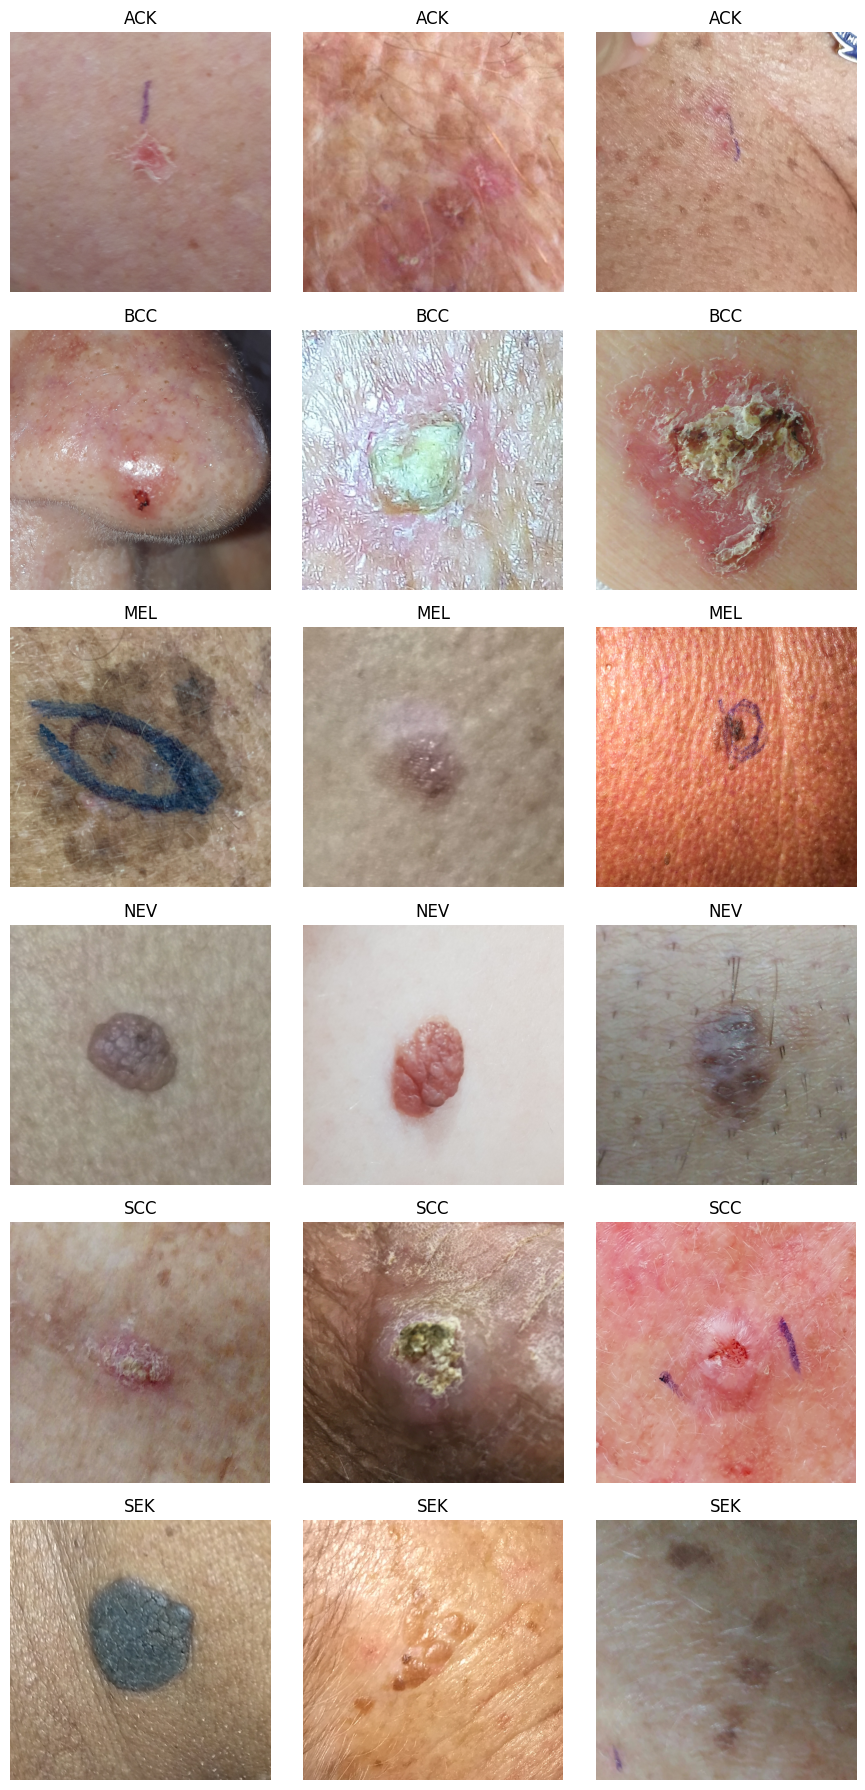

In [34]:
classes = sorted(df["diagnostic"].unique())

fig, axes = plt.subplots(
    len(classes),
    3,
    figsize=(9, 3 * len(classes))
)

for row, label in enumerate(classes):
    samples = (
        df[df["diagnostic"] == label]
        .sample(n=3, random_state=42)
    )

    for col, (_, sample) in enumerate(samples.iterrows()):
        image = Image.open(image_paths[sample["img_id"]])

        axes[row, col].imshow(image)
        axes[row, col].axis("off")
        axes[row, col].set_title(label)

plt.tight_layout()
plt.show()

## 18. Summarise Image Shape Characteristics

Summarise image dimensions and aspect-ratio variation to guide the later image preprocessing strategy.

In [35]:
square_exact = (image_df["width"] == image_df["height"]).sum()

approximately_square = (
    image_df["aspect_ratio"].between(0.95, 1.05)
).sum()

aspect_outliers = len(image_df) - approximately_square

print(f"Exactly square images: {square_exact}")
print(
    f"Approximately square images (0.95–1.05): "
    f"{approximately_square}"
)
print(f"Aspect-ratio outliers: {aspect_outliers}")

Exactly square images: 1876
Approximately square images (0.95–1.05): 2289
Aspect-ratio outliers: 9


## 19. Class Structure by Patient and Lesion

Count images, unique patients, and unique lesions within each diagnostic class.

This helps assess whether class imbalance is also present at the patient level rather than only at the image level.

In [36]:
class_structure = (
    df.groupby("diagnostic")
    .agg(
        images=("img_id", "count"),
        patients=("patient_id", "nunique"),
        lesions=("lesion_id", "nunique"),
    )
    .sort_index()
)

display(class_structure)

,images,patients,lesions
diagnostic,,,
ACK,730,525,621
BCC,845,513,652
MEL,52,36,36
NEV,244,185,215
SCC,192,133,145
SEK,235,176,198


## 20. Create Patient-Grouped Cross-Validation Folds

Create five stratified cross-validation folds using patient ID as the grouping variable.

This prevents images from the same patient appearing in both training and validation data while approximately preserving class distributions.

In [37]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

df["fold"] = -1

for fold, (_, val_idx) in enumerate(
    cv.split(
        X=df,
        y=df["diagnostic"],
        groups=df["patient_id"],
    )
):
    df.loc[val_idx, "fold"] = fold

print(df["fold"].value_counts().sort_index())

fold
0    460
1    441
2    448
3    459
4    490
Name: count, dtype: int64


## 21. Inspect Fold Class Distributions

Check the diagnostic-class distribution of each validation fold to confirm that the grouped split remains reasonably balanced.

In [38]:
fold_distribution = pd.crosstab(
    df["fold"],
    df["diagnostic"]
)

display(fold_distribution)

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
fold,,,,,,
0,144,173,13,45,37,48
1,135,171,9,48,35,43
2,127,175,5,54,38,49
3,170,134,14,51,42,48
4,154,192,11,46,40,47


## 22. Validate Patient Separation

Confirm that no patient occurs in both the training and validation partitions for any fold.

In [39]:
for fold in sorted(df["fold"].unique()):
    train_patients = set(
        df.loc[df["fold"] != fold, "patient_id"]
    )

    val_patients = set(
        df.loc[df["fold"] == fold, "patient_id"]
    )

    overlap = train_patients & val_patients

    print(
        f"Fold {fold}: "
        f"{len(train_patients)} train patients, "
        f"{len(val_patients)} validation patients, "
        f"{len(overlap)} overlapping patients"
    )

    assert len(overlap) == 0

print("\n✓ No patient leakage detected.")

Fold 0: 1100 train patients, 273 validation patients, 0 overlapping patients
Fold 1: 1096 train patients, 277 validation patients, 0 overlapping patients
Fold 2: 1097 train patients, 276 validation patients, 0 overlapping patients
Fold 3: 1099 train patients, 274 validation patients, 0 overlapping patients
Fold 4: 1100 train patients, 273 validation patients, 0 overlapping patients

✓ No patient leakage detected.


## 23. Inspect Minority-Class Coverage Across Folds

Inspect melanoma coverage across folds because melanoma is the smallest diagnostic class and therefore the most sensitive to grouped splitting.

In [40]:
mel_df = df[df["diagnostic"] == "MEL"]

mel_fold_summary = (
    mel_df.groupby("fold")
    .agg(
        images=("img_id", "count"),
        patients=("patient_id", "nunique"),
        lesions=("lesion_id", "nunique"),
    )
)

display(mel_fold_summary)

,images,patients,lesions
fold,,,
0,13,9,9
1,9,6,6
2,5,4,4
3,14,10,10
4,11,7,7


## 24. Define Final Metadata Feature Set

Define the clinical metadata variables retained for the primary multimodal experiments.

Identifiers, the target variable, biopsy status, and variables with strongly structured cohort-linked missingness are excluded from model input.

In [41]:
SAFE_METADATA = [
    "age",
    "region",
    "itch",
    "grew",
    "hurt",
    "changed",
    "bleed",
    "elevation",
]

EXCLUDED_IDENTIFIERS = [
    "patient_id",
    "lesion_id",
    "img_id",
]

EXCLUDED_TARGET = [
    "diagnostic",
]

EXCLUDED_WORKFLOW = [
    "biopsed",
]

print("Primary metadata features:")
for feature in SAFE_METADATA:
    print("-", feature)

Primary metadata features:
- age
- region
- itch
- grew
- hurt
- changed
- bleed
- elevation


## 25. Validate Final Metadata Features

Confirm that the selected metadata variables are present and contain no missing values before model preprocessing.

In [42]:
assert all(
    feature in df.columns
    for feature in SAFE_METADATA
)

safe_missing = df[SAFE_METADATA].isna().sum()

display(safe_missing.to_frame("missing_values"))

assert safe_missing.sum() == 0

print("\n✓ Final metadata feature set validated.")

,missing_values
age,0
region,0
itch,0
grew,0
hurt,0
changed,0
bleed,0
elevation,0



✓ Final metadata feature set validated.


## 26. Save Fixed Fold Assignments

Save the audited metadata together with the fixed patient-grouped fold assignments.

All benchmark and proposed models will use these same folds to ensure fair and reproducible comparison.

In [44]:
OUTPUT_PATH = (
    PROJECT_ROOT
    / "pad_ufes_20_with_folds.csv"
)

df.to_csv(OUTPUT_PATH, index=False)

print(f"Saved: {OUTPUT_PATH}")
print(f"Rows: {len(df)}")

Saved: /content/drive/MyDrive/PAD_UFES_Capstone/pad_ufes_20_with_folds.csv
Rows: 2298


## 27. Audit Summary

The dataset audit established the following modelling decisions:

- PAD-UFES-20 contains 2,298 clinical images paired with structured clinical metadata.
- The dataset is strongly class-imbalanced, with melanoma (MEL) as the smallest class.
- Most images are approximately square, although image resolution varies substantially.
- All 2,298 metadata image IDs were successfully matched to extracted image files.
- Multiple images and lesions can belong to the same patient, and some patients have more than one diagnosis.
- Patient-level grouping is therefore required to prevent patient leakage between training and validation data.
- Five fixed stratified patient-grouped cross-validation folds are used for all experiments, with no patient overlap between training and validation partitions.
- Identifier variables (`patient_id`, `lesion_id`, and `img_id`) are excluded from predictive features.
- `biopsed` is excluded because it reflects the diagnostic workflow and is strongly associated with diagnosis.
- A structured 13-variable missingness pattern affecting 804 samples is strongly associated with particular diagnostic classes. These cohort-linked variables are therefore excluded from the primary experiment.
- The primary clinical metadata features are:
  - `age`
  - `region`
  - `itch`
  - `grew`
  - `hurt`
  - `changed`
  - `bleed`
  - `elevation`
- The selected primary metadata features contain no missing values.
- The same fixed fold assignments will be reused across all benchmark and proposed models to support fair paired comparison.